# Task 7: Demand Forecasting

Run `python src/forecast.py` first. It forecasts weekly new roles per company over a shared 8-week horizon from `weekly_postings.csv` (Task 5), with the same candidate models and the same backtest for all four. Target: `new_roles_adjusted` (survivorship-adjusted unique new roles). With 26 weekly points, no seasonality (under a year of data) and no deep learning, the candidates are simple, listed here in order of simplicity: naive, 4-week moving average, simple exponential smoothing, drift, damped Holt, ARIMA (small grid by AIC) and Prophet with seasonality off. The chosen model is the simplest one within one standard error of the best backtest error (the one-SE rule). Intervals are empirical, from backtest errors.

Treat every forecast as uncertain: the adjusted series is itself an estimate (correction capped at 3x), and its growth moved about 30 points between two snapshots.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
P = "../data/processed/"
weekly = pd.read_csv(P + "weekly_postings.csv", parse_dates=["week_start"]).dropna(subset=["new_roles_unique"])
fc = pd.read_csv(P + "forecasts.csv", parse_dates=["week_start"])
bt = pd.read_csv(P + "backtest_metrics.csv")
sens = pd.read_csv(P + "forecast_sensitivity.csv", parse_dates=["week_start"])
cc = pd.read_csv(P + "forecast_crosscheck.csv")

ORDER = ["OpenAI", "Anthropic", "Databricks", "NVIDIA"]
COLOR = {"OpenAI": "#1c5cab", "Anthropic": "#d9772b", "Databricks": "#b5342c", "NVIDIA": "#3f8f2f"}
GREY = "#8b949e"
MODELS = ["naive", "ma4", "ses", "drift", "holt_damped", "arima", "prophet"]      # fixed simplicity order
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
chosen = bt[(bt.target == "adjusted") & bt.chosen].set_index("company_name")
chosen[["model", "mae", "rel_mae", "origin_mae", "origin_mae_se", "n_origins"]].reindex(ORDER)

,model,mae,rel_mae,origin_mae,origin_mae_se,n_origins
company_name,,,,,,
OpenAI,ma4,17.19,0.741,18.91,1.93,12
Anthropic,naive,20.25,1.000,19.20,2.53,12
Databricks,ma4,11.83,0.846,12.66,1.01,12
NVIDIA,holt_damped,50.73,0.837,55.88,9.84,11


## 1. Forecast fan charts

History (adjusted, solid; unique roles, faint), the chosen model's 8-week forecast, and empirical 80% and 95% intervals from backtest errors, clipped at 0. The dotted line is the last complete week. NVIDIA's data ends a week earlier than the others, so its forecast starts a week earlier.

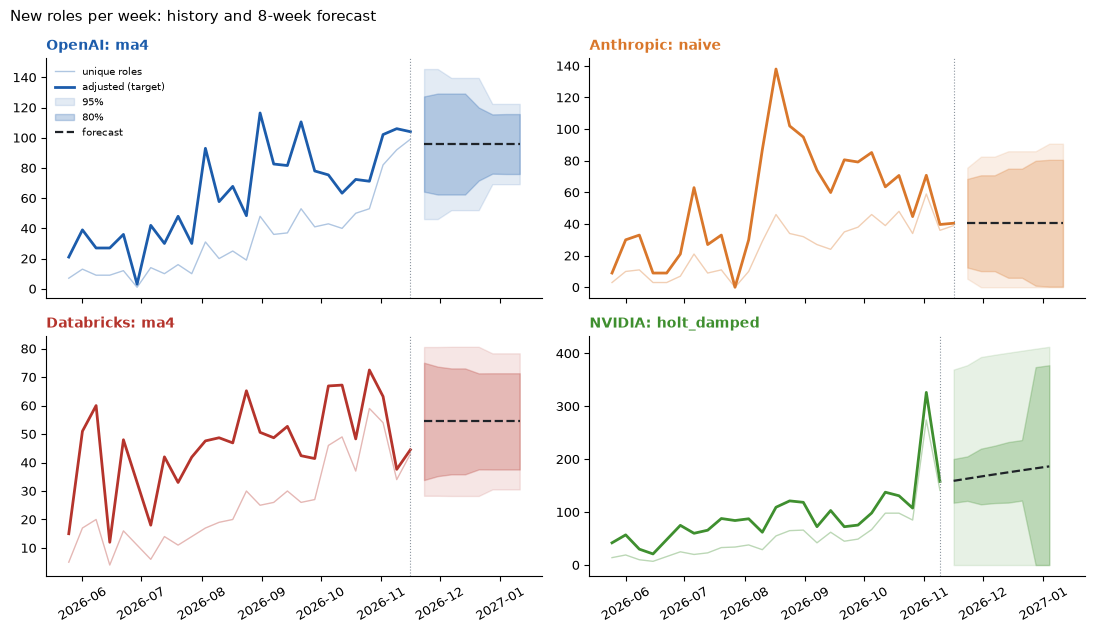

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.4), sharex=True)
for ax, c in zip(axes.flat, ORDER):
    h = weekly[weekly.company_name == c]; f = fc[fc.company_name == c]
    ax.plot(h.week_start, h.new_roles_unique, color=COLOR[c], lw=1, alpha=.35, label="unique roles")
    ax.plot(h.week_start, h.new_roles_adjusted, color=COLOR[c], lw=2, label="adjusted (target)")
    ax.fill_between(f.week_start, f.lo95, f.hi95, color=COLOR[c], alpha=.12, label="95%")
    ax.fill_between(f.week_start, f.lo80, f.hi80, color=COLOR[c], alpha=.25, label="80%")
    ax.plot(f.week_start, f.forecast, color="#1f2328", lw=1.6, ls="--", label="forecast")
    ax.axvline(h.week_start.max(), color=GREY, lw=.8, ls=":")
    ax.set_title(f"{c}: {f.model.iloc[0]}", loc="left", fontsize=10, color=COLOR[c], fontweight="bold")
    ax.tick_params(axis="x", rotation=30)
axes[0, 0].legend(fontsize=7, frameon=False, loc="upper left")
fig.suptitle("New roles per week: history and 8-week forecast", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()

**Reading it:** OpenAI's moving average gives a flat forecast near 96 roles a week, with an 80% band of roughly 62 to 129. Anthropic's naive forecast is 40.5 a week with an 80% band of about 0 to 81. Databricks is also flat (54.4). NVIDIA's damped Holt rises from 159 to 186, and its bands are very wide (the 95% band reaches 0 to about 410) because the week of 2 Nov produced large backtest errors. The bands do not widen smoothly with the horizon: with 11 to 12 origins the data cannot resolve how error grows over 8 weeks.

## 2. Backtest and model choice

Rolling origin, expanding window, first origin after 14 weeks, up to 8 weeks ahead. Each model's error at an origin is its mean absolute error over the steps forecast from there. The chart shows the mean across origins with one standard error. The dashed line is the best model's mean plus one SE; the **chosen** model (star) is the simplest model under that line (order: naive, 4-week average, SES, drift, damped Holt, ARIMA, Prophet).

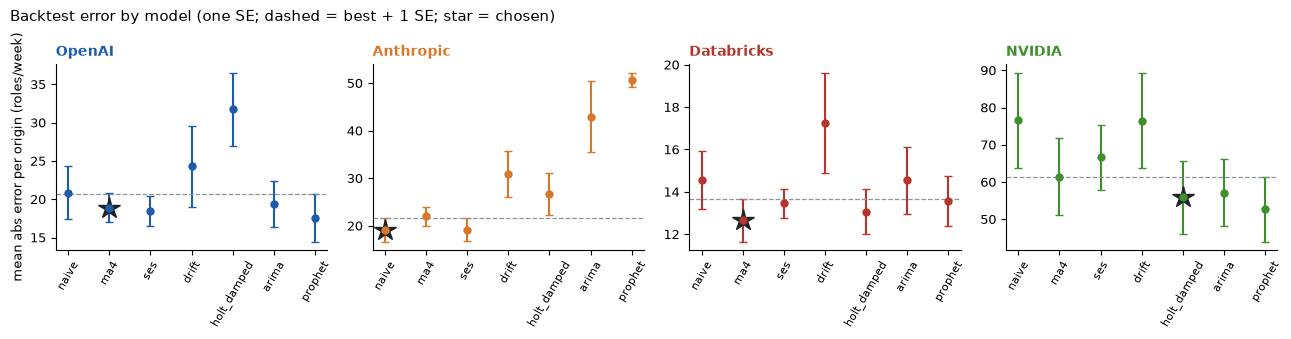

Relative MAE (backtest MAE / naive backtest MAE on the same origins and steps; below 1 beats naive)


company_name,OpenAI,Anthropic,Databricks,NVIDIA
model,,,,
naive,1.00,1.00,1.00,1.00
ma4,0.74,1.11,0.85,0.90
ses,0.77,1.00,0.97,0.94
drift,1.24,1.73,1.19,1.01
holt_damped,1.55,1.48,0.84,0.84
arima,0.98,2.49,0.90,0.89
prophet,0.94,2.52,0.87,0.80


In [3]:
a = bt[bt.target == "adjusted"].set_index(["company_name", "model"])
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharey=False)
for ax, c in zip(axes, ORDER):
    d = a.loc[c].reindex(MODELS)
    ax.errorbar(range(len(MODELS)), d.origin_mae, yerr=d.origin_mae_se, fmt="o", color=COLOR[c], capsize=3, ms=5)
    ax.axhline(d.one_se_threshold.iloc[0], color=GREY, ls="--", lw=.9)
    j = MODELS.index(chosen.loc[c, "model"]); ax.plot(j, d.origin_mae.iloc[j], marker="*", ms=16, color="#1f2328", ls="")
    ax.set_xticks(range(len(MODELS)), MODELS, rotation=60, fontsize=8)
    ax.set_title(c, loc="left", fontsize=10, color=COLOR[c], fontweight="bold")
axes[0].set_ylabel("mean abs error per origin (roles/week)")
fig.suptitle("Backtest error by model (one SE; dashed = best + 1 SE; star = chosen)", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()
m = a.reset_index().pivot(index="model", columns="company_name", values="rel_mae").reindex(MODELS)[ORDER]
print("Relative MAE (backtest MAE / naive backtest MAE on the same origins and steps; below 1 beats naive)")
m.round(2)

**Reading it:** the one-SE rule picks the 4-week moving average for OpenAI and Databricks, naive for Anthropic, and damped Holt for NVIDIA. For OpenAI, Prophet has the lowest mean error but is inside the same one-SE band as the moving average, so the simpler model wins. For Anthropic naive is itself the best, and nothing has a relative MAE below 1. Anthropic's SES ties it (1.00). For NVIDIA damped Holt is the simplest model inside the band (Prophet is lowest). Relative MAE is the backtest MAE divided by naive's, not the classical in-sample-scaled MASE.

Do the same models win on the unadjusted series? Backtest on `new_roles_unique`:

In [4]:
mu = bt[bt.target == "unique"].pivot(index="model", columns="company_name", values="rel_mae").reindex(MODELS)[ORDER]
print("Best by per-origin error:", bt[(bt.target == "unique") & bt.best_model].set_index("company_name").model.reindex(ORDER).to_dict())
print("Chosen by one-SE:        ", bt[(bt.target == "unique") & bt.chosen].set_index("company_name").model.reindex(ORDER).to_dict())
mu.round(2)

Best by per-origin error: {'OpenAI': 'drift', 'Anthropic': 'ma4', 'Databricks': 'prophet', 'NVIDIA': 'prophet'}
Chosen by one-SE:         {'OpenAI': 'drift', 'Anthropic': 'ma4', 'Databricks': 'prophet', 'NVIDIA': 'ma4'}


company_name,OpenAI,Anthropic,Databricks,NVIDIA
model,,,,
naive,1.00,1.00,1.00,1.00
ma4,1.13,0.92,1.06,1.00
ses,1.06,0.98,1.03,0.99
drift,0.84,0.96,0.85,0.91
holt_damped,0.86,0.92,0.85,0.91
arima,0.79,0.96,0.79,0.83
prophet,0.78,0.78,0.82,0.79


**Reading it:** on the unadjusted series Prophet or ARIMA reaches a relative MAE of 0.78 to 0.79 for every company, the clearest gain over naive anywhere in this task. On the adjusted series the gain from trend models is weaker and uneven. That is consistent with the unadjusted series carrying the survivorship ramp, which trend models extrapolate and the adjustment largely removes. It is a reason to forecast the adjusted series, not a sign that trend models are better.

## 3. Interval calibration

Share of backtest actuals inside the chosen model's intervals. Model-based: the Gaussian interval from the model's own standard error. Empirical: half-width from the model's absolute backtest errors at that step (neighbouring steps pooled until 20 errors), validated leave-one-origin-out.

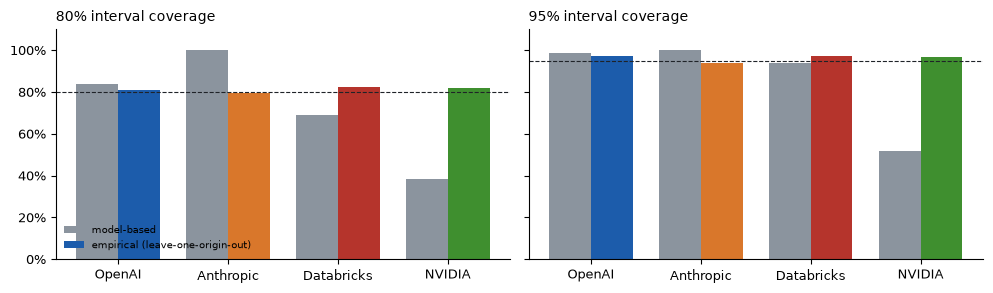

,model,coverage80_model,coverage80_empirical,coverage95_model,coverage95_empirical
company_name,,,,,
OpenAI,ma4,0.838,0.809,0.985,0.971
Anthropic,naive,1.000,0.794,1.000,0.941
Databricks,ma4,0.691,0.824,0.941,0.971
NVIDIA,holt_damped,0.383,0.817,0.517,0.967


In [5]:
c = chosen.loc[ORDER]
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, lvl in zip(axes, ("80", "95")):
    x = np.arange(4); w = .38
    ax.bar(x - w/2, c[f"coverage{lvl}_model"], w, color=GREY, label="model-based")
    ax.bar(x + w/2, c[f"coverage{lvl}_empirical"], w, color=[COLOR[k] for k in ORDER], label="empirical (leave-one-origin-out)")
    ax.axhline(int(lvl) / 100, color="#1f2328", ls="--", lw=.8)
    ax.set_xticks(x, ORDER); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_ylim(0, 1.1)
    ax.set_title(f"{lvl}% interval coverage", loc="left", fontsize=10)
axes[0].legend(frameon=False, fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()
c[["model", "coverage80_model", "coverage80_empirical", "coverage95_model", "coverage95_empirical"]]

**Reading it:** the model-based intervals are miscalibrated where it matters: for the chosen NVIDIA model only 38% of actuals fall inside the 80% band and 52% inside the 95% band, and for Databricks 69% and 94%. The empirical intervals are close to nominal for all four (79% to 82% at 80%, 94% to 97% at 95%). The cost is width: where errors are large (NVIDIA), the intervals are very wide. The check is leave-one-origin-out, so it is not circular, but it does reuse errors from later origins.

## 4. Sensitivity

Two checks on the chosen model: the unique-roles target (no survivorship adjustment) and a refit on August onwards, because earlier weeks are floors where the correction hits its 3x cap.

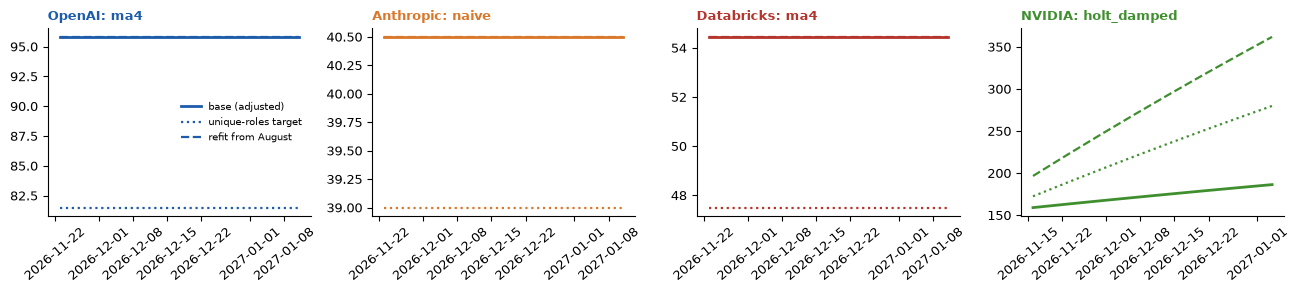

weeks_fitted               mean_forecast                \
scenario      from_august unique_target   from_august unique_target   
company_name                                                          
OpenAI                 16            26          95.8          81.5   
Anthropic              16            26          40.5          39.0   
Databricks             16            26          54.4          47.5   
NVIDIA                 15            25         280.9         227.3   

               mean_base               mean_diff_pct                
scenario     from_august unique_target   from_august unique_target  
company_name                                                        
OpenAI              95.8          95.8           0.0         -14.9  
Anthropic           40.5          40.5           0.0          -3.7  
Databricks          54.4          54.4           0.0         -12.8  
NVIDIA             173.0         173.0          61.2          30.7

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharex=False)
STYLE = {"base": ("-", 2, "base (adjusted)"), "unique_target": (":", 1.6, "unique-roles target"), "from_august": ("--", 1.6, "refit from August")}
for ax, c in zip(axes, ORDER):
    for sc, (ls, lw, lab) in STYLE.items():
        d = sens[(sens.company_name == c) & (sens.scenario == sc)]
        ax.plot(d.week_start, d.forecast, color=COLOR[c], ls=ls, lw=lw, label=lab)
    ax.set_title(f"{c}: {sens[sens.company_name == c].model.iloc[0]}", loc="left", fontsize=9, color=COLOR[c], fontweight="bold")
    ax.tick_params(axis="x", rotation=40)
axes[0].legend(fontsize=7, frameon=False)
plt.tight_layout(); plt.show()
s = sens[sens.scenario != "base"].groupby(["company_name", "scenario"]).agg(
    weeks_fitted=("n_weeks_fitted", "first"), mean_forecast=("forecast", "mean"), mean_base=("base_forecast", "mean"),
    mean_diff_pct=("diff_pct", "mean")).round(1)
s.unstack("scenario").reindex(ORDER)

**Reading it:** refitting from August changes nothing for OpenAI, Anthropic and Databricks, because the moving average and naive use only the last few weeks. For NVIDIA it raises the damped Holt forecast by about 61%, so NVIDIA's trend is not stable and its forecast is the least reliable. The unique-roles target gives lower levels for OpenAI (15% lower), Databricks (13%) and Anthropic (4%), which mostly reflects the survival adjustment itself. For NVIDIA it gives a higher forecast (31%) probably because the trend model extrapolates the survivorship ramp in the unadjusted series.

## 5. Cross-check against snapshot inflow

The forecast level for the next 2 weeks against the unbiased snapshot `opened_per_week`. NVIDIA's flows are provisional (one interval).

In [7]:
cc.set_index("company_name").reindex(ORDER)

,model,forecast_next2_mean,snapshot_opened_per_week,ratio,flows_provisional
company_name,,,,,
OpenAI,ma4,95.8,82.5,1.16,False
Anthropic,naive,40.5,44.6,0.91,False
Databricks,ma4,54.4,50.1,1.09,False
NVIDIA,holt_damped,161.2,145.8,1.11,True


**Reading it:** the forecasts sit within 16% of the snapshot inflow for every company (ratios 0.91 to 1.16), tighter than the Task 5 comparison of the latest two weeks with the same flows (0.82 to 1.27 for the three companies with full flows), as expected from a smoothed forecast. NVIDIA's 1.16 is provisional.